In [ ]:
import numpy as numpy
import matplotlib.pyplot as pyplot


R = 5

x = np.linspace(-R, R, 200)
y = np.linspace(-R, R, 200)
X, Y = np.meshgrid =(x, y)

Z_Squared = R**2 - X**2 - Y**2

z = np.sqrt(np.maximum(Z_squared,0))

z[Z_Squared<0] = np.nan

P = -X/Z
Q = -Y/Z



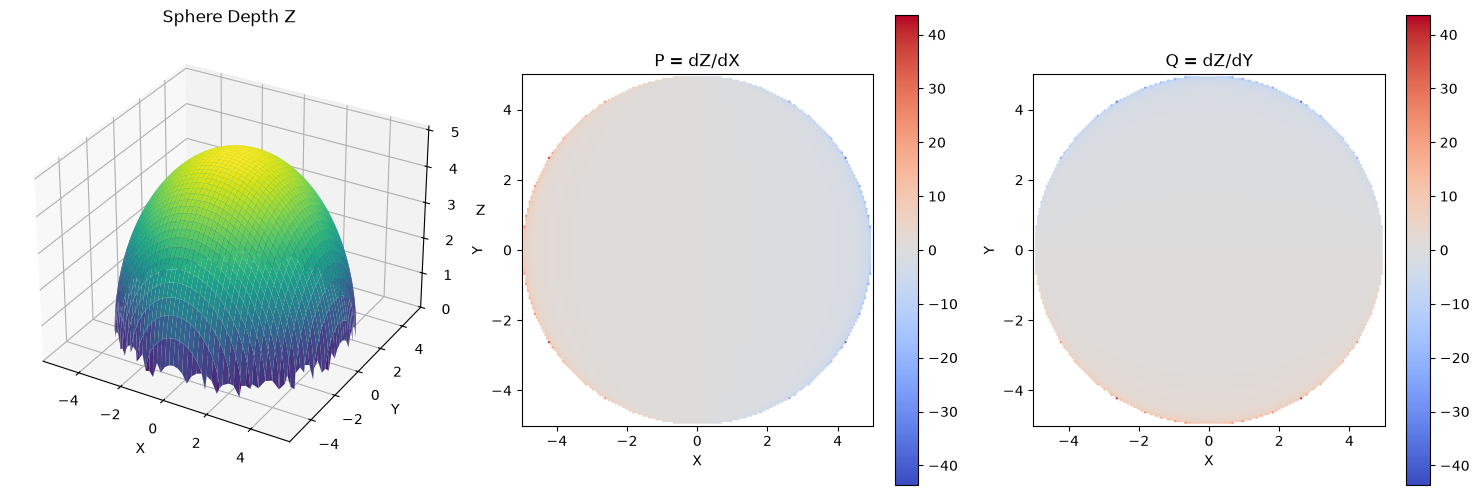

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sphere radius
R = 5

# Generate coordinates
x = np.linspace(-R, R, 200)
y = np.linspace(-R, R, 200)
X, Y = np.meshgrid(x, y)

# Sphere equation: x^2 + y^2 + z^2 = R^2
Z_squared = R**2 - X**2 - Y**2
Z = np.sqrt(np.maximum(Z_squared, 0))

# Mask points outside the sphere
Z[Z_squared < 0] = np.nan

# Calculate surface gradients p and q
P = -X / Z
Q = -Y / Z

# Avoid division by zero near the sphere boundary
P[Z < 1e-6] = np.nan
Q[Z < 1e-6] = np.nan

# Plot depth, p, and q
fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis')
ax1.set_title('Sphere Depth Z')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

ax2 = fig.add_subplot(132)
im1 = ax2.imshow(P, extent=[-R, R, -R, R],
                 origin='lower', cmap='coolwarm')
ax2.set_title('P = dZ/dX')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
plt.colorbar(im1, ax=ax2)

ax3 = fig.add_subplot(133)
im2 = ax3.imshow(Q, extent=[-R, R, -R, R],
                 origin='lower', cmap='coolwarm')
ax3.set_title('Q = dZ/dY')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
plt.colorbar(im2, ax=ax3)

plt.tight_layout()
plt.show()

/tmp/ipykernel_5138/3710083007.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


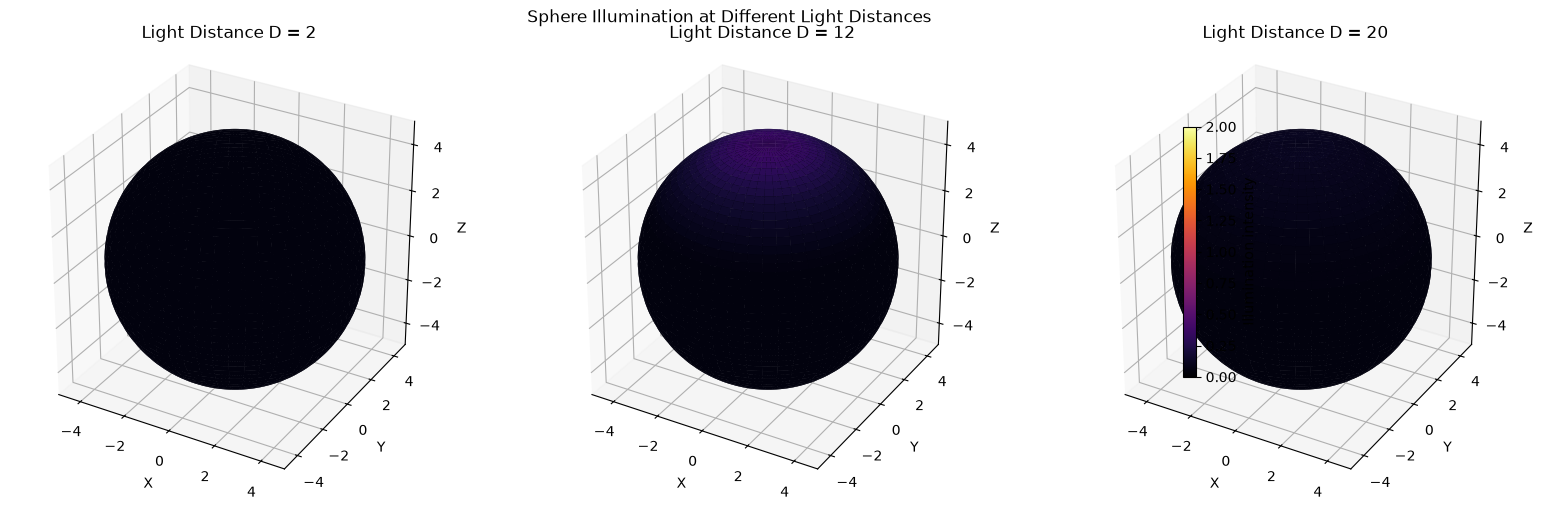

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

# Sphere parameters
R = 5
theta = np.linspace(0, 2 * np.pi, 150)
phi = np.linspace(0, np.pi, 100)
THETA, PHI = np.meshgrid(theta, phi)

# Sphere coordinates
X = R * np.sin(PHI) * np.cos(THETA)
Y = R * np.sin(PHI) * np.sin(THETA)
Z = R * np.cos(PHI)

# Unit surface normals for a sphere centered at origin
NX = X / R
NY = Y / R
NZ = Z / R

# Lighting parameters
ambient = 0.05
Kd = 0.8
IL = 20

# Light-source distances from sphere center
light_distances = [2, 12, 20]

# Fixed color scale for fair comparison
norm = Normalize(vmin=0, vmax=2.0)
cmap = cm.inferno

fig = plt.figure(figsize=(16, 5))

for i, D in enumerate(light_distances):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')

    # Point light positioned above the sphere
    LX, LY, LZ = 0, 0, D

    # Vector from each surface point toward the light
    dx = LX - X
    dy = LY - Y
    dz = LZ - Z

    # Distance from each surface point to the light
    distance = np.sqrt(dx**2 + dy**2 + dz**2)

    # Normalize light direction
    lx = dx / distance
    ly = dy / distance
    lz = dz / distance

    # Lambertian diffuse reflection
    cos_theta = np.maximum(
        0, NX * lx + NY * ly + NZ * lz
    )

    # Inverse-square distance attenuation
    intensity = ambient + (
        Kd * IL * cos_theta / distance**2
    )

    # Apply illumination as surface colors
    facecolors = cmap(norm(intensity))

    ax.plot_surface(
        X, Y, Z,
        facecolors=facecolors,
        linewidth=0,
        antialiased=True,
        shade=False
    )

    ax.set_title(f'Light Distance D = {D}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlim(-R, R)
    ax.set_ylim(-R, R)
    ax.set_zlim(-R, R)

# Shared illumination colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(
    sm, ax=fig.axes,
    shrink=0.65, label='Illumination intensity'
)

plt.suptitle('Sphere Illumination at Different Light Distances')
plt.tight_layout()
plt.show()


/tmp/ipykernel_5138/2371049876.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


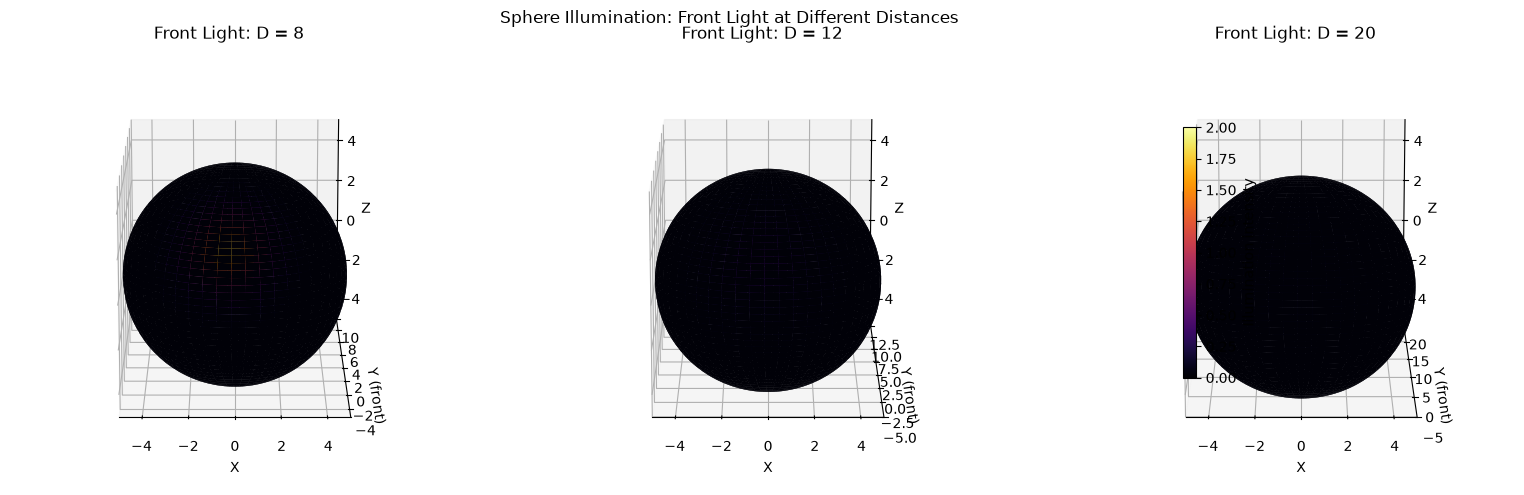

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

R = 5

theta = np.linspace(0, 2 * np.pi, 150)
phi = np.linspace(0, np.pi, 100)
THETA, PHI = np.meshgrid(theta, phi)

# Sphere coordinates
X = R * np.sin(PHI) * np.cos(THETA)
Y = R * np.sin(PHI) * np.sin(THETA)
Z = R * np.cos(PHI)

# Surface unit normals
NX, NY, NZ = X / R, Y / R, Z / R

# Illumination parameters
ambient = 0.03
Kd = 0.8
IL = 20
light_distances = [8, 12, 20]

norm = Normalize(vmin=0, vmax=2.0)
cmap = cm.inferno

fig = plt.figure(figsize=(16, 5))

for i, D in enumerate(light_distances):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')

    # Light in front: along positive Y-axis
    LX, LY, LZ = 0, D, 0

    # Direction from each surface point to the light
    dx = LX - X
    dy = LY - Y
    dz = LZ - Z

    distance = np.sqrt(dx**2 + dy**2 + dz**2)

    lx = dx / distance
    ly = dy / distance
    lz = dz / distance

    # Lambertian diffuse illumination
    cos_theta = np.maximum(
        0, NX * lx + NY * ly + NZ * lz
    )

    intensity = ambient + (
        Kd * IL * cos_theta / distance**2
    )

    ax.plot_surface(
        X, Y, Z,
        facecolors=cmap(norm(intensity)),
        linewidth=0,
        antialiased=True,
        shade=False
    )

    # Mark the light source
    ax.scatter(
        [LX], [LY], [LZ],
        color='yellow', edgecolor='black',
        s=100, label='Light source'
    )

    ax.set_title(f'Front Light: D = {D}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y (front)')
    ax.set_zlabel('Z')
    ax.set_xlim(-R, R)
    ax.set_ylim(-R, D + 2)
    ax.set_zlim(-R, R)
    ax.set_box_aspect([1, 1.5, 1])
    ax.view_init(elev=15, azim=-90)

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(
    sm, ax=fig.axes,
    shrink=0.65, label='Illumination intensity'
)

plt.suptitle('Sphere Illumination: Front Light at Different Distances')
plt.tight_layout()
plt.show()


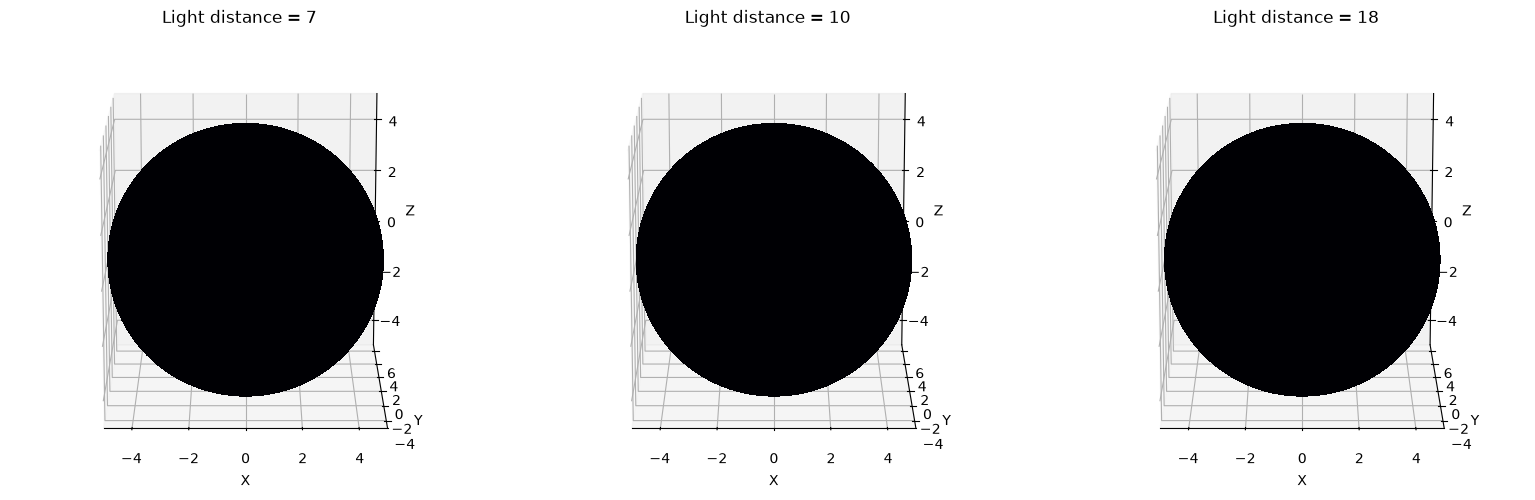

In [5]:

import numpy as np
import matplotlib.pyplot as plt

R = 5
u = np.linspace(0, 2 * np.pi, 200)
v = np.linspace(0, np.pi, 120)
U, V = np.meshgrid(u, v)

# Sphere coordinates
X = R * np.sin(V) * np.cos(U)
Y = R * np.sin(V) * np.sin(U)
Z = R * np.cos(V)

# Surface normals
NX, NY, NZ = X / R, Y / R, Z / R

# Light distances from sphere center
distances = [7, 10, 18]

fig = plt.figure(figsize=(16, 5))

for i, D in enumerate(distances):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    # Light directly in front (+Y direction)
    L = np.array([0.0, D, 0.0])

    # Vector from surface to light
    DX = L[0] - X
    DY = L[1] - Y
    DZ = L[2] - Z

    d = np.sqrt(DX**2 + DY**2 + DZ**2)

    # Unit light direction
    lx, ly, lz = DX/d, DY/d, DZ/d

    # Lambert's cosine law
    cos_theta = np.maximum(0, NX*lx + NY*ly + NZ*lz)

    # Distance attenuation, with ambient light
    I = 0.08 + 25 * cos_theta / d**2

    # Normalize each image for visible shading
    I_norm = (I - I.min()) / (I.max() - I.min() + 1e-9)

    ax.plot_surface(
        X, Y, Z,
        facecolors=plt.cm.magma(I_norm),
        rstride=1, cstride=1,
        linewidth=0, antialiased=False,
        shade=False
    )

    ax.scatter(*L, color="cyan", s=80, label="Light")
    ax.set_title(f"Light distance = {D}")
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlim(-R, R)
    ax.set_ylim(-R, R + 2)
    ax.set_zlim(-R, R)

    # Look from the front (+Y direction)
    ax.view_init(elev=15, azim=-90)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

plt.tight_layout()
plt.show()


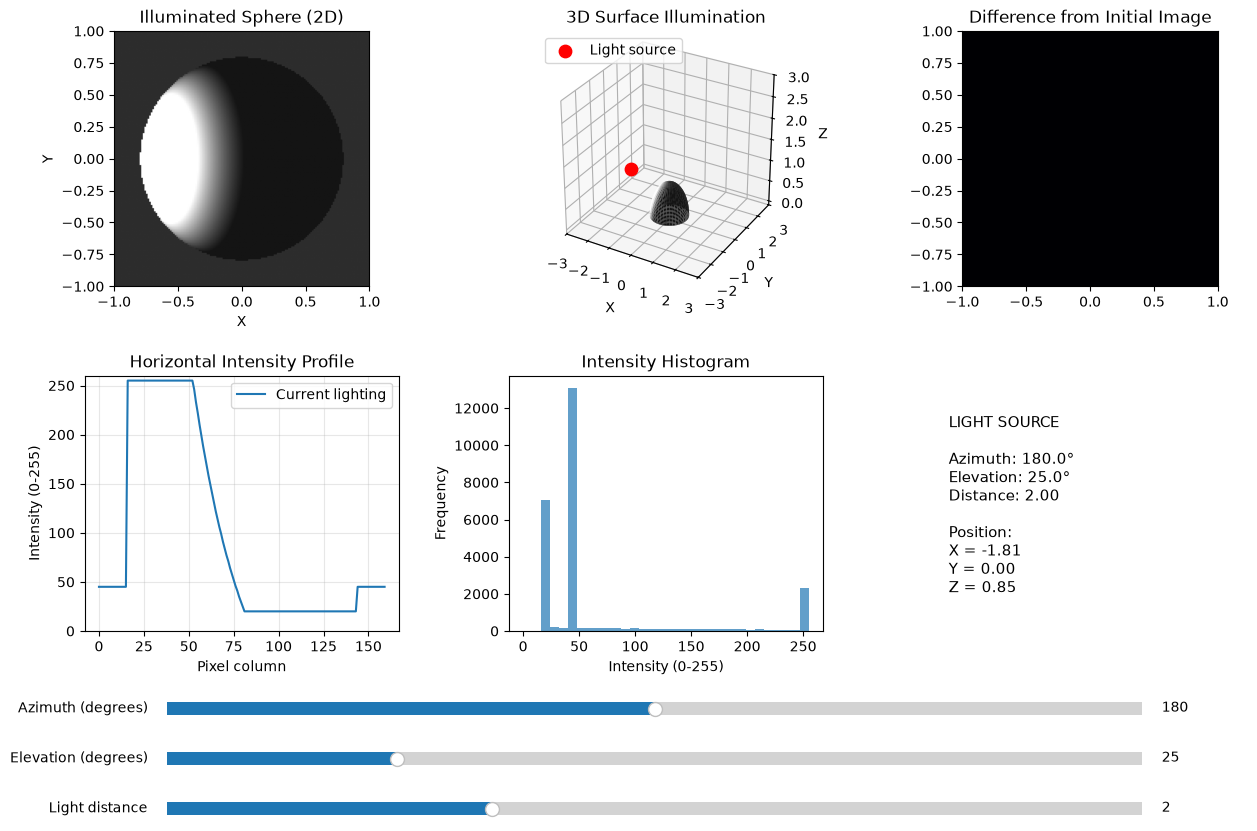

In [13]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# 1. GENERATE SPHERE AND SURFACE NORMALS
# ============================================================

R = 0.8
n = 160

y, x = np.mgrid[-1:1:160j, -1:1:160j]
r2 = x**2 + y**2
sphere_mask = r2 <= R**2

# 3D surface coordinates
z = np.zeros_like(x)
z[sphere_mask] = np.sqrt(R**2 - r2[sphere_mask])

# Surface normals
Nx = np.zeros_like(x)
Ny = np.zeros_like(y)
Nz = np.zeros_like(z)

Nx[sphere_mask] = x[sphere_mask] / R
Ny[sphere_mask] = y[sphere_mask] / R
Nz[sphere_mask] = z[sphere_mask] / R

# ============================================================
# 2. ILLUMINATION MODEL
# ============================================================

ambient = 0.08
light_power = 4.0

def calculate_illumination(azimuth, elevation, distance):
    """
    Angles are in degrees.
    Distance is measured from the sphere center.
    """

    az = np.radians(azimuth)
    el = np.radians(elevation)

    # Point light source position
    Lx = distance * np.cos(el) * np.cos(az)
    Ly = distance * np.cos(el) * np.sin(az)
    Lz = distance * np.sin(el)

    # Vector from each surface point to the light
    dx = Lx - x
    dy = Ly - y
    dz = Lz - z

    # Distance from each surface point to the light
    d = np.sqrt(dx**2 + dy**2 + dz**2)
    d = np.maximum(d, 1e-6)

    # Normalize light direction at each surface point
    lx = dx / d
    ly = dy / d
    lz = dz / d

    # Lambertian diffuse reflection: N dot L
    diffuse = np.maximum(
        Nx * lx + Ny * ly + Nz * lz, 0
    )

    # Distance-dependent illumination (inverse-square law)
    intensity = ambient + light_power * diffuse / d**2

    # Background plane
    image = np.full_like(x, 0.18)

    # Apply illumination only to the sphere
    image[sphere_mask] = intensity[sphere_mask]

    # Approximate cast shadow on the plane
    shadow = (
        (~sphere_mask)
        & (x > 0.35)
        & (np.abs(y) < 0.65)
        & (azimuth < 180)
    )
    image[shadow] = 0.04

    return np.clip(image, 0, 1), (Lx, Ly, Lz)


# ============================================================
# 3. INITIAL ILLUMINATION
# ============================================================

initial_azimuth = 180
initial_elevation = 25
initial_distance = 2.0

image, light_pos = calculate_illumination(
    initial_azimuth,
    initial_elevation,
    initial_distance
)

image_8u = (image * 255).astype(np.uint8)

# ============================================================
# 4. CREATE VISUALIZATION
# ============================================================

fig = plt.figure(figsize=(15, 10))
fig.subplots_adjust(bottom=0.28, wspace=0.35, hspace=0.35)

ax_img = fig.add_subplot(231)
ax_3d = fig.add_subplot(232, projection="3d")
ax_diff = fig.add_subplot(233)
ax_profile = fig.add_subplot(234)
ax_hist = fig.add_subplot(235)
ax_info = fig.add_subplot(236)

# 2D illuminated image
im = ax_img.imshow(
    image_8u, cmap="gray", vmin=0, vmax=255,
    extent=[-1, 1, -1, 1], origin="upper"
)
ax_img.set_title("Illuminated Sphere (2D)")
ax_img.set_xlabel("X")
ax_img.set_ylabel("Y")

# 3D sphere surface
theta = np.linspace(0, 2 * np.pi, 120)
phi = np.linspace(0, np.pi / 2, 80)

# Visible hemisphere z >= 0
TH, PH = np.meshgrid(theta, phi)
X3 = R * np.sin(PH) * np.cos(TH)
Y3 = R * np.sin(PH) * np.sin(TH)
Z3 = R * np.cos(PH)

def sphere_colors(az, el, dist):
    # Calculate illumination at 3D surface points
    azr, elr = np.radians(az), np.radians(el)

    light = np.array([
        dist * np.cos(elr) * np.cos(azr),
        dist * np.cos(elr) * np.sin(azr),
        dist * np.sin(elr)
    ])

    points = np.stack([X3, Y3, Z3], axis=-1)
    normals = points / R

    vectors = light - points
    distances = np.maximum(
        np.linalg.norm(vectors, axis=-1), 1e-6
    )
    directions = vectors / distances[..., None]

    ndotl = np.maximum(
        np.sum(normals * directions, axis=-1), 0
    )

    brightness = ambient + light_power * ndotl / distances**2
    brightness = np.clip(brightness, 0, 1)

    # Grayscale face colors
    return plt.cm.gray(brightness)

surface = ax_3d.plot_surface(
    X3, Y3, Z3,
    facecolors=sphere_colors(
        initial_azimuth, initial_elevation, initial_distance
    ),
    linewidth=0, antialiased=True, shade=False
)

light_marker = ax_3d.scatter(
    [light_pos[0]], [light_pos[1]], [light_pos[2]],
    color="red", s=80, label="Light source"
)

ax_3d.set_title("3D Surface Illumination")
ax_3d.set_xlabel("X")
ax_3d.set_ylabel("Y")
ax_3d.set_zlabel("Z")
ax_3d.set_xlim(-3, 3)
ax_3d.set_ylim(-3, 3)
ax_3d.set_zlim(-0.1, 3)
ax_3d.set_box_aspect((1, 1, 1))
ax_3d.legend(loc="upper left")

# Difference image
diff = np.zeros_like(image_8u, dtype=float)
diff_im = ax_diff.imshow(
    diff, cmap="magma", vmin=0, vmax=255,
    extent=[-1, 1, -1, 1]
)
ax_diff.set_title("Difference from Initial Image")

# Horizontal intensity profile
row = 80
line1, = ax_profile.plot(
    image_8u[row, :], label="Current lighting"
)
ax_profile.set_title("Horizontal Intensity Profile")
ax_profile.set_xlabel("Pixel column")
ax_profile.set_ylabel("Intensity (0-255)")
ax_profile.set_ylim(0, 260)
ax_profile.grid(True, alpha=0.3)
ax_profile.legend()

# Histogram
hist1 = ax_hist.hist(
    image_8u.ravel(), bins=32, range=(0, 255),
    alpha=0.7
)
ax_hist.set_title("Intensity Histogram")
ax_hist.set_xlabel("Intensity (0-255)")
ax_hist.set_ylabel("Frequency")

# Light parameters
ax_info.axis("off")
info_text = ax_info.text(
    0.05, 0.85, "", fontsize=11, va="top"
)

# ============================================================
# 5. INTERACTIVE SLIDERS
# ============================================================

ax_az = fig.add_axes([0.18, 0.19, 0.65, 0.025])
ax_el = fig.add_axes([0.18, 0.14, 0.65, 0.025])
ax_dist = fig.add_axes([0.18, 0.09, 0.65, 0.025])

s_az = Slider(
    ax_az, "Azimuth (degrees)",
    0, 360, valinit=initial_azimuth
)
s_el = Slider(
    ax_el, "Elevation (degrees)",
    5, 90, valinit=initial_elevation
)
s_dist = Slider(
    ax_dist, "Light distance",
    1.0, 4.0, valinit=initial_distance
)

initial_image = image_8u.copy()

# ============================================================
# 6. UPDATE ALL VISUALIZATIONS
# ============================================================

def update(val):
    global surface, light_marker

    az = s_az.val
    el = s_el.val
    dist = s_dist.val

    new_image, light_pos = calculate_illumination(
        az, el, dist
    )
    new_8u = (new_image * 255).astype(np.uint8)

    # Update 2D image
    im.set_data(new_8u)

    # Update 3D surface illumination
    surface.remove()
    surface = ax_3d.plot_surface(
        X3, Y3, Z3,
        facecolors=sphere_colors(az, el, dist),
        linewidth=0, antialiased=True, shade=False
    )

    # Update light marker
    light_marker.remove()
    light_marker = ax_3d.scatter(
        [light_pos[0]], [light_pos[1]], [light_pos[2]],
        color="red", s=80
    )

    # Update difference map
    diff_im.set_data(
        np.abs(new_8u.astype(float) - initial_image.astype(float))
    )

    # Update profile
    line1.set_ydata(new_8u[row, :])

    # Update histogram
    ax_hist.clear()
    ax_hist.hist(
        new_8u.ravel(), bins=32, range=(0, 255),
        alpha=0.7
    )
    ax_hist.set_title("Intensity Histogram")
    ax_hist.set_xlabel("Intensity (0-255)")
    ax_hist.set_ylabel("Frequency")

    # Update light information
    info_text.set_text(
        f"LIGHT SOURCE\n\n"
        f"Azimuth: {az:.1f}°\n"
        f"Elevation: {el:.1f}°\n"
        f"Distance: {dist:.2f}\n\n"
        f"Position:\n"
        f"X = {light_pos[0]:.2f}\n"
        f"Y = {light_pos[1]:.2f}\n"
        f"Z = {light_pos[2]:.2f}"
    )

    fig.canvas.draw_idle()


s_az.on_changed(update)
s_el.on_changed(update)
s_dist.on_changed(update)

update(None)
plt.show()
